> **Bản PyTorch** của `examples/4. Training Utilities/3_Emotion_Reg_CNN.ipynb` (Keras). Người chuyển: TV3 – Võ Hoàng Bảo. Theo khuôn `2. CNN + MLP/3_Emotion_Reg_CNN` và `4. Training Utilities/2_Human_Gender_CNN` của BTL03.
>
> **Thay đổi so với bản Keras**
>
> - Đọc thẳng `fer2013.csv` (lọc `Usage = Training` → 28 709 ảnh train, `Usage = PublicTest` → 3 589 ảnh test), giữ nguyên giá trị pixel thô `0–255` như bản gốc và khuôn `3_Emotion_Reg_CNN`; in 3 pixel đầu (`70, 80, 82`) để đối chiếu.
> - Ảnh `(N, 48, 48, 1)` → `(N, 1, 48, 48)`; nhãn là chỉ số lớp `0..6` thay vì one-hot.
> - Mô hình giữ nguyên kiến trúc CNN + MLP (**19,028,287 tham số**, giữ filter `218`, `Flatten = 218·9·9 = 17 658`, bỏ `softmax` cuối để dùng `nn.CrossEntropyLoss()`, khởi tạo trọng số `xavier_uniform_` + bias `0` giống Keras).
> - **Data Augmentation**: thay `keras.preprocessing.image.ImageDataGenerator(rotation_range=45, width_shift_range=0.2, height_shift_range=0.2, horizontal_flip=True)` bằng lớp `AugmentedEmotionDataset(Dataset)` kết hợp `torchvision.transforms` (`RandomHorizontalFlip(p=0.5)` + `RandomAffine(degrees=45, translate=(0.2, 0.2))`), chỉ áp dụng trên tập train và giữ nguyên thang pixel `0–255`.
> - **EarlyStopping**: thay `keras.callbacks.EarlyStopping(monitor='val_loss', patience=5)` bằng lớp `EarlyStopping` tự viết (chép theo khuôn `4. Training Utilities/2_Human_Gender_CNN`) trong vòng lặp `fit_with_early_stopping`.
> - Cố định `SEED = 0`, bật `torch.backends.cudnn.deterministic = True` và tắt `benchmark` để kết quả tái lập được.

# Overview
### Data augmentation + EarlyStopping to avoid overfitting
- FER2013 dataset (face images + facial expression)
  + Goal: classifying facial expression
  + Input: a 48x48 image
  + Output: facial expression (angry, disgust, fear, happy, neutral, sad, and surprise)
- Defining an CNN+MLP
- Training and evaluating an CNN+MLP

# Import libraries

In [1]:
import os
import time
from collections import OrderedDict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch import nn
from torch.utils.data import Dataset, TensorDataset, DataLoader
from torchvision import transforms

SEED = 0
np.random.seed(SEED)
torch.manual_seed(SEED)
# cuDNN mặc định chọn thuật toán nhanh nhưng không tất định -> chạy lại cùng seed vẫn ra số hơi khác.
# Tắt để mỗi lần Run All cho cùng kết quả (chậm hơn một chút).
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# Keras tự dùng GPU nếu có; PyTorch phải chọn thiết bị và chuyển model, dữ liệu sang thiết bị đó
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('torch', torch.__version__, '| device:', device, torch.cuda.get_device_name(0) if device.type == 'cuda' else '')

torch 2.6.0+cu124 | device: cuda NVIDIA GeForce RTX 3050 Laptop GPU


# Hàm huấn luyện (thay cho `model.summary`, `model.fit`, `model.evaluate`, `model.predict`)
Keras có sẵn các hàm này; PyTorch thì tự viết vòng lặp. Mỗi notebook tự chứa các hàm dưới đây (chép từ khuôn), không phụ thuộc file code nào khác.

In [2]:
def summary(model, input_size):
    """Tương đương model.summary(): in tên lớp, kích thước đầu ra, số tham số."""
    rows, hooks = [], []
    for name, m in model.named_modules():
        if len(list(m.children())) == 0:
            hooks.append(m.register_forward_hook(
                lambda mod, inp, out, name=name: rows.append((name, type(mod).__name__, tuple(out.shape), sum(p.numel() for p in mod.parameters())))))
    model.eval()
    with torch.no_grad():
        model(torch.zeros(1, *input_size, device=device))
    for h in hooks:
        h.remove()
    print(f"{'Layer (type)':<36}{'Output Shape':<24}{'Param #':>10}")
    print('=' * 70)
    for name, typ, shape, n in rows:
        print(f"{name + ' (' + typ + ')':<36}{str((None,) + shape[1:]):<24}{n:>10,}")
    print('=' * 70)
    print(f"Total params: {sum(p.numel() for p in model.parameters()):,}")


def init_like_keras(model):
    """Keras khởi tạo Dense/Conv2D bằng glorot_uniform và bias = 0; PyTorch mặc định dùng kaiming_uniform.
    Khởi tạo giống Keras để kết quả sát bản gốc (nhất là khi đầu vào là pixel thô 0–255)."""
    for m in model.modules():
        if isinstance(m, (nn.Linear, nn.Conv2d, nn.ConvTranspose2d)):
            nn.init.xavier_uniform_(m.weight)
            nn.init.zeros_(m.bias)


def train_one_epoch(model, loader, loss_fn, optimizer):
    """Một epoch huấn luyện; trả về (loss, accuracy) trung bình trên tập train như Keras in ra."""
    model.train()                      # bật Dropout
    total_loss, correct, n = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        logits = model(x)
        loss = loss_fn(logits, y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(y)
        correct += (logits.argmax(1) == y).sum().item()
        n += len(y)
    return total_loss / n, correct / n


def evaluate(model, loader, loss_fn):
    """Tương đương model.evaluate(): trả về (loss, accuracy) trên cả tập."""
    model.eval()                       # tắt Dropout
    total_loss, correct, n = 0.0, 0, 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            logits = model(x)
            total_loss += loss_fn(logits, y).item() * len(y)
            correct += (logits.argmax(1) == y).sum().item()
            n += len(y)
    return total_loss / n, correct / n


def predict(model, x, batch_size=512):
    """Tương đương model.predict(): trả về xác suất softmax dạng numpy."""
    model.eval()
    out = []
    with torch.no_grad():
        for i in range(0, len(x), batch_size):
            xb = torch.as_tensor(np.asarray(x[i:i + batch_size]), dtype=torch.float32, device=device)
            out.append(torch.softmax(model(xb), dim=1).cpu().numpy())
    return np.concatenate(out)


def plot_history(history):
    """Vẽ loss/accuracy theo epoch từ history (Keras trả về History.history, ở đây là dict)."""
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    for i, m in enumerate(['loss', 'accuracy']):
        ax[i].plot(range(1, len(history[m]) + 1), history[m], label='train')
        ax[i].plot(range(1, len(history['val_' + m]) + 1), history['val_' + m], label='validation')
        ax[i].set_xlabel('epoch'); ax[i].set_ylabel(m); ax[i].legend(); ax[i].grid(alpha=.3)
    plt.show()


def make_loader(x, y, batch_size, shuffle):
    """Mảng numpy -> DataLoader (thay cho việc truyền thẳng x, y vào model.fit)."""
    ds = TensorDataset(torch.tensor(np.asarray(x), dtype=torch.float32), torch.tensor(np.asarray(y), dtype=torch.long))
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle)

### Training utilities (thay cho `ImageDataGenerator` và `keras.callbacks.EarlyStopping`)

In [3]:
class AugmentedEmotionDataset(Dataset):
    """Thay cho ImageDataGenerator.flow(x, y): áp dụng torchvision.transforms trực tiếp lên tensor (1, 48, 48)."""
    def __init__(self, x, y, transform=None):
        self.x = torch.tensor(np.asarray(x), dtype=torch.float32)
        self.y = torch.tensor(np.asarray(y), dtype=torch.long)
        self.transform = transform

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        img = self.x[idx]
        if self.transform is not None:
            img = self.transform(img)
        return img, self.y[idx]


class EarlyStopping:
    """Như keras.callbacks.EarlyStopping(monitor='val_loss', patience=...): dừng khi val_loss không giảm `patience` epoch liên tiếp."""
    def __init__(self, patience):
        self.patience, self.wait, self.best = patience, 0, float('inf')

    def step(self, val_loss):
        if val_loss < self.best:
            self.best, self.wait = val_loss, 0
        else:
            self.wait += 1
        return self.wait >= self.patience


def fit_with_early_stopping(model, train_loader, val_loader, loss_fn, optimizer, epochs, early_stopping):
    """Tương đương model.fit_generator(..., callbacks=[early_stopping])."""
    history = {'loss': [], 'accuracy': [], 'val_loss': [], 'val_accuracy': []}
    for epoch in range(1, epochs + 1):
        t0 = time.time()
        loss, acc = train_one_epoch(model, train_loader, loss_fn, optimizer)
        val_loss, val_acc = evaluate(model, val_loader, loss_fn)
        for k, v in zip(history, (loss, acc, val_loss, val_acc)):
            history[k].append(v)
        print(f'Epoch {epoch}/{epochs} - {time.time() - t0:.1f}s - loss: {loss:.4f} - accuracy: {acc:.4f}'
              f' - val_loss: {val_loss:.4f} - val_accuracy: {val_acc:.4f}')
        if early_stopping.step(val_loss):
            print(f'Epoch {epoch}: early stopping (best val_loss={early_stopping.best:.4f})')
            break
    return history

In [4]:
num_classes = 7   # angry, disgust, fear, happy, sad, surprise, neutral (thứ tự nhãn của Kaggle)

# (1) Data
Đặt `fer2013.csv` cạnh notebook, hoặc để ở `BTL02/data/fer2013.csv` của repo (xem `PHAN_CONG_NHIEM_VU.md` mục 3).

In [5]:
candidates = ['fer2013.csv', '../../../BTL02/data/fer2013.csv']
fer_path = next(p for p in candidates if os.path.exists(p))
df = pd.read_csv(fer_path)
print(fer_path, df.shape)
print(df['Usage'].value_counts())

def load_split(usage):
    sub = df[df['Usage'] == usage]
    x = np.stack([np.fromstring(p, dtype=np.float32, sep=' ') for p in sub['pixels']])   # (N, 2304)
    return x, sub['emotion'].to_numpy()

x_training, y_training = load_split('Training')      # = fer2013_training_onehot.csv
x_testing, y_testing = load_split('PublicTest')      # = fer2013_publictest_onehot.csv
print('3 pixel đầu của ảnh train đầu tiên:', x_training[0, :3])   # Keras gốc: [70, 80, 82]

../../../BTL02/data/fer2013.csv (35887, 3)
Usage
Training       28709
PublicTest      3589
PrivateTest     3589
Name: count, dtype: int64


3 pixel đầu của ảnh train đầu tiên: [70. 80. 82.]


In [6]:
n_inputs = 2304
img_dim = 48

# Keras: (N, 48, 48, 1)  ->  PyTorch: (N, 1, 48, 48)
x_training = x_training.reshape(x_training.shape[0], 1, img_dim, img_dim)
x_testing = x_testing.reshape(x_testing.shape[0], 1, img_dim, img_dim)
print(x_training.shape, y_training.shape, x_testing.shape, y_testing.shape)

(28709, 1, 48, 48) (28709,) (3589, 1, 48, 48) (3589,)


# (2) Declare model

In [7]:
model = nn.Sequential(OrderedDict([
    # conv, pooling layers + dropout
    ('conv1_1', nn.Conv2d(1, 64, 3, padding=1)), ('relu1_1', nn.ReLU()),       # 'same'
    ('conv1_2', nn.Conv2d(64, 64, 3, padding=0)), ('relu1_2', nn.ReLU()),      # 'valid'
    ('pool1', nn.MaxPool2d(2)), ('conv_dropout1', nn.Dropout(0.25)),
    ('conv2_1', nn.Conv2d(64, 128, 3, padding=1)), ('relu2_1', nn.ReLU()),
    ('conv2_2', nn.Conv2d(128, 128, 3, padding=0)), ('relu2_2', nn.ReLU()),
    ('conv2_3', nn.Conv2d(128, 218, 3, padding=1)), ('relu2_3', nn.ReLU()),
    ('conv2_4', nn.Conv2d(218, 218, 3, padding=0)), ('relu2_4', nn.ReLU()),
    ('pool2', nn.MaxPool2d(2)), ('conv_dropout2', nn.Dropout(0.25)),
    # similar to the MLP example!
    ('flatten', nn.Flatten()),
    ('fc1', nn.Linear(218 * 9 * 9, 1024)), ('relu_fc1', nn.ReLU()), ('fc_dropout1', nn.Dropout(0.5)),
    ('fc3', nn.Linear(1024, num_classes)),     # 7 lớp, softmax nằm trong CrossEntropyLoss
])).to(device)
init_like_keras(model)
summary(model, (1, 48, 48))   # Keras: 19,028,287 tham số

Layer (type)                        Output Shape               Param #
conv1_1 (Conv2d)                    (None, 64, 48, 48)             640
relu1_1 (ReLU)                      (None, 64, 48, 48)               0
conv1_2 (Conv2d)                    (None, 64, 46, 46)          36,928
relu1_2 (ReLU)                      (None, 64, 46, 46)               0
pool1 (MaxPool2d)                   (None, 64, 23, 23)               0
conv_dropout1 (Dropout)             (None, 64, 23, 23)               0
conv2_1 (Conv2d)                    (None, 128, 23, 23)         73,856
relu2_1 (ReLU)                      (None, 128, 23, 23)              0
conv2_2 (Conv2d)                    (None, 128, 21, 21)        147,584
relu2_2 (ReLU)                      (None, 128, 21, 21)              0
conv2_3 (Conv2d)                    (None, 218, 21, 21)        251,354
relu2_3 (ReLU)                      (None, 218, 21, 21)              0
conv2_4 (Conv2d)                    (None, 218, 19, 19)        427,934
relu2_

# (3) Train defined model
- Note that the training history including loss and accuracy will be saved in `history` variable
- In case your system runs out of memory (OOM), try to decrease batch size

In [8]:
# Data augmentation (thay cho keras.preprocessing.image.ImageDataGenerator)
# Keras gốc: rotation_range=45, width_shift_range=0.2, height_shift_range=0.2, horizontal_flip=True
train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomAffine(
        degrees=45,
        translate=(0.2, 0.2),
        interpolation=transforms.InterpolationMode.BILINEAR,
    ),
])

In [9]:
# declare learning rate, loss function, and optimizer
loss_fn = nn.CrossEntropyLoss()
lr = 0.0001
optimizer = torch.optim.Adam(model.parameters(), lr=lr)

# EarlyStopping: stop training early to avoid overfitting
early_stopping_after_epochs = 5
early_stopping = EarlyStopping(patience=early_stopping_after_epochs)

# train the model
batch_size = 128
epochs = 100

train_ds = AugmentedEmotionDataset(x_training, y_training, transform=train_transform)
train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
test_loader = make_loader(x_testing, y_testing, batch_size, shuffle=False)

starting_time = time.time()
history = fit_with_early_stopping(model, train_loader, test_loader, loss_fn, optimizer, epochs, early_stopping)
print('> training time is %.4f minutes' % ((time.time() - starting_time) / 60))

Epoch 1/100 - 30.6s - loss: 2.3242 - accuracy: 0.2299 - val_loss: 1.8524 - val_accuracy: 0.2499


Epoch 2/100 - 31.6s - loss: 1.8230 - accuracy: 0.2464 - val_loss: 1.8225 - val_accuracy: 0.2544


Epoch 3/100 - 31.8s - loss: 1.8143 - accuracy: 0.2462 - val_loss: 1.8177 - val_accuracy: 0.2569


Epoch 4/100 - 31.4s - loss: 1.8050 - accuracy: 0.2539 - val_loss: 1.7751 - val_accuracy: 0.2678


Epoch 5/100 - 31.0s - loss: 1.7981 - accuracy: 0.2568 - val_loss: 1.7715 - val_accuracy: 0.2719


Epoch 6/100 - 31.0s - loss: 1.7894 - accuracy: 0.2569 - val_loss: 1.7431 - val_accuracy: 0.2809


... (40 outputs left out)

Epoch 47/100 - 31.0s - loss: 1.1189 - accuracy: 0.5793 - val_loss: 1.0693 - val_accuracy: 0.5965


Epoch 48/100 - 30.9s - loss: 1.1093 - accuracy: 0.5847 - val_loss: 1.0675 - val_accuracy: 0.5946


Epoch 49/100 - 31.0s - loss: 1.1014 - accuracy: 0.5883 - val_loss: 1.0745 - val_accuracy: 0.5949


Epoch 50/100 - 30.9s - loss: 1.0954 - accuracy: 0.5900 - val_loss: 1.0862 - val_accuracy: 0.5893
Epoch 50: early stopping (best val_loss=1.0531)
> training time is 25.8699 minutes


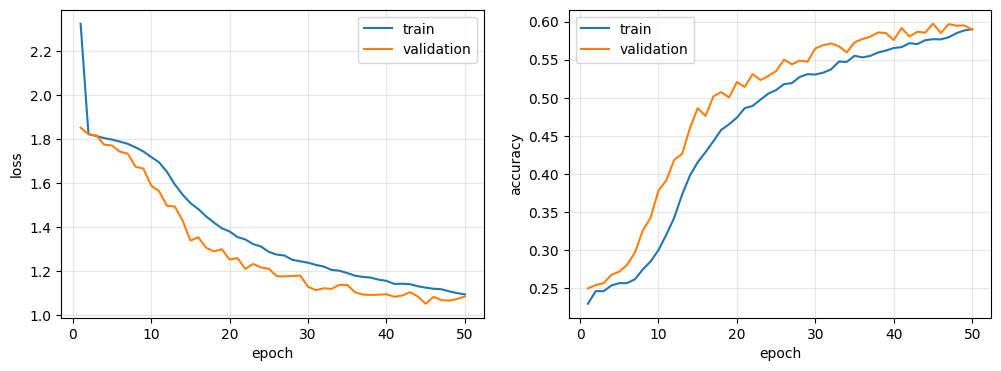

In [10]:
plot_history(history)

### Training time
- Bản Keras gốc (GTX 1080): 22.7489 phút cho 57 epoch (EarlyStopping), Test loss 1.0158, Test accuracy 0.6163 (+2% so với bản không augmentation)
- Bản PyTorch: xem kết quả ô trên (NVIDIA GeForce RTX 3050 Laptop GPU)

# (4) Evaluate trained model

In [11]:
score = evaluate(model, test_loader, loss_fn)
print('Test loss:', score[0])
print('Test accuracy:', score[1])

Test loss: 1.086248477875738
Test accuracy: 0.5893006408470326


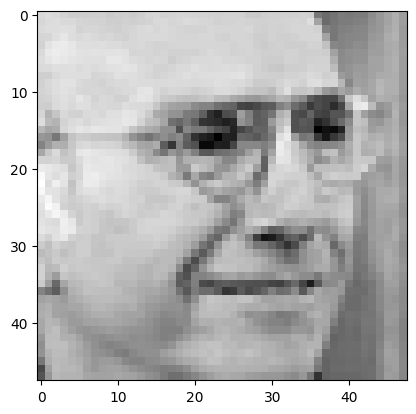

> testing image index: 1969
> true emotion: happy
> predicted emotion: happy


In [12]:
EMOTIONS = ['angry', 'disgust', 'fear', 'happy', 'sad', 'surprise', 'neutral']

def get_emotion(label_or_probs):
    """Nhận chỉ số lớp hoặc vector xác suất, trả về tên cảm xúc (giống hàm get_emotion bản gốc)."""
    return EMOTIONS[int(np.argmax(label_or_probs)) if np.ndim(label_or_probs) else int(label_or_probs)]

img_indx = np.uint32(np.random.rand() * (x_testing.shape[0] - 1))
sample = x_testing[img_indx]
pred_cls = predict(model, sample.reshape(1, 1, 48, 48))

plt.imshow(sample.reshape(48, 48), cmap='gray')
plt.show()
print('> testing image index: %d\n> true emotion: %s\n> predicted emotion: %s'
      % (img_indx, get_emotion(y_testing[img_indx]), get_emotion(pred_cls)))